# Early warning: results for the slide deck

All results at **15 bp, 2-24 h lead**. Numbers come from `slides/compute_calibrated.py` (main results) and
`slides/compute_results.py` (appendix), run with the project `.venv`; this notebook only reads `slides/data/*.csv`
and writes the figures to `slides/figures/` (transparent PNG, 300 dpi, legends outside the axes).

**Protocol.** An *event* is a declustered onset of |depeg| >= 15 bp (24 h reset). A warning is *timely* if it comes
2-24 h before onset; alerts are grouped into episodes (12 h cooldown); an alert with no onset 2-24 h later is a false
alert. **CV:** 4 expanding-window folds over 2024, 18 events. **Holdout:** 2025-01-15 to 2026-05-06, 5 events, never
used for fitting, selection or calibration.

**Threshold-free summary (section 5).** Decision curves of the *raw* probabilities, summarised by the weighted
area under the net-benefit curve (WA-NBC, Talluri & Shete 2016): no cutoff and no calibration map is fitted, so
nothing can overfit one period. Ex post AUVC is kept in Appendix A as a ranking measure only.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path
DATA, FIG = Path("data"), Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "legend.frameon": False,
                     "savefig.dpi": 300, "savefig.transparent": True, "savefig.bbox": "tight"})
# fixed colour per model (never by rank); forecast-derived = solid, direct classifiers = dashed, |d| = dotted
STYLE = {
    "ANGEL exceedance": dict(color="#2a78d6", ls="-",  lw=3.0),
    "ARIMA":            dict(color="#8e5bd0", ls="-",  lw=2.0),
    "GARCH-t":          dict(color="#eda100", ls="-",  lw=2.0),
    "TiDE forecast":    dict(color="#1baf7a", ls="-",  lw=2.0),
    "TimeXer forecast": dict(color="#a0522d", ls="-",  lw=2.0),
    "Kumo":             dict(color="#eb6834", ls="--", lw=2.0),
    "TabICL":           dict(color="#c2185b", ls="--", lw=2.0),
    "Random forest":    dict(color="#556b2f", ls="--", lw=2.0),
    "CatBoost":         dict(color="#00a3c4", ls="--", lw=2.0),
    "ANGEL classifier": dict(color="#2a78d6", ls="--", lw=1.6),
    "|d| now":          dict(color="#555555", ls=":",  lw=2.0),
}
FAMILY_COLOR = {"forecast": "#2a78d6", "classifier": "#eb6834"}
CV_SHOW = ["ANGEL exceedance", "ARIMA", "GARCH-t", "TiDE forecast", "TimeXer forecast",
           "Kumo", "Random forest", "CatBoost", "ANGEL classifier"]
HO_SHOW = ["ANGEL exceedance", "ARIMA", "GARCH-t", "TiDE forecast", "TimeXer forecast", "Kumo", "Random forest", "CatBoost"]
R = np.round(np.arange(0.01, 0.501, 0.01), 4)
HPM = 730.5

def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

grid = pd.read_csv(DATA / "calibrated_policy_grid.csv")
grid["p"] = grid.p.round(4)

COLS = ["D", "N", "A", "F", "H", "avoided", "perfect"]
def runs(period, model, calibration="calibrated", split="test"):
    # tallies per (run, p), summed over CV folds
    g = grid[grid.period.eq(period) & grid.model.eq(model) & grid.calibration.eq(calibration) & grid.split.eq(split)]
    return g.groupby(["run", "p"])[COLS].sum().reset_index()

def V(D, A, N, r):                      # standard cost-loss value
    return (D - r * A) / (N * (1 - r))

def V_lead(avoided, perfect, A, N, r):  # lead-time-aware value, fixed cost per episode C = r x mean perfect loss
    C = r * perfect / N
    return (avoided - C * A) / (perfect - C * N)

def fixed_policy_curve(period, model, p=0.1, calibration="calibrated", lead=False):
    g = runs(period, model, calibration); g = g[g.p.eq(p)]
    f = (lambda t: V_lead(t.avoided, t.perfect, t.A, t.N, R)) if lead else (lambda t: V(t.D, t.A, t.N, R))
    return np.mean([f(t) for t in g.itertuples()], axis=0)

def gain(t, r, lead):                    # numerator of V: what the policy saves (division-free, safe with N = 0)
    return (t.avoided - r * t.perfect / np.maximum(t.N, 1) * t.A) if lead else (t.D - r * t.A)

def selected_curve(period, model, lead=False):
    # deployable envelope: for each r, p chosen WITHOUT the evaluation data, then valued on it
    # (CV: per fold on its validation block; holdout: on the model's pooled 2024 CV test-fold results)
    g = grid[grid.model.eq(model) & grid.calibration.eq("calibrated")]
    f = (lambda t, r: V_lead(t.avoided, t.perfect, t.A, t.N, r)) if lead else (lambda t, r: V(t.D, t.A, t.N, r))
    out = []
    if period == "CV":
        cv = g[g.period.eq("CV")]
        for run, gr in cv.groupby("run"):
            vals = []
            for r in R:
                tot = pd.Series(0.0, index=COLS)
                for k, gf in gr.groupby("fold"):
                    v = gf[gf.split.eq("validation")].set_index("p"); t = gf[gf.split.eq("test")].set_index("p")
                    gv = gain(v, r, lead)
                    if gv.max() > 0:
                        tot += t.loc[gv.idxmax(), COLS]
                    else:                                   # never alert: only the events count
                        tot["N"] += t.N.iloc[0]; tot["perfect"] += t.perfect.iloc[0]
                vals.append(f(tot, r))
            out.append(vals)
    else:
        pooled = g[g.period.eq("CV") & g.split.eq("test")].groupby("p")[COLS].sum()
        ho = runs("holdout", model)
        for run, t in ho.groupby("run"):
            t = t.set_index("p"); vals = []
            for r in R:
                gv = gain(pooled, r, lead)
                if gv.max() > 0:
                    vals.append(f(t.loc[gv.idxmax()], r))
                else:
                    vals.append(0.0)
            out.append(vals)
    return np.mean(out, axis=0)

def rule_curve(period, model, calibration="calibrated", lead=False):
    """Each user acts on its own ratio: policy p = r, valued at r."""
    out = []
    for _, g in runs(period, model, calibration).groupby("run"):
        g = g.set_index("p").loc[R]
        out.append(V_lead(g.avoided, g.perfect, g.A, g.N, R) if lead else V(g.D, g.A, g.N, R))
    return np.mean(out, axis=0)

## 1. Two ways to build a warning score

* **Direct classifier** (benchmark): learn P(onset in 2-24 h | x_t) from the event label. Tree ensembles (random
  forest, CatBoost), tabular foundation models (Kumo, TabICL) and sequence classifiers (the ANGEL network trained
  on the label).
* **Forecast-derived**: read the warning off the probabilistic forecaster, S_t = max_{h=2..24} P(|d_{t+h}| >= 15 bp).
  No extra training on the rare label; same quantile forecasts as in the forecasting section (ANGEL, ARIMA, GARCH-t,
  TiDE, TimeXer).

## 2. Cost-loss value

A user pays **C** each time they act on a warning and loses **L** if an event hits unprotected; r = C/L. Over N
events, with D caught and A alert episodes:

V(r) = (D - r A) / (N (1 - r)) — share of the perfect warning system's saving. 1 = perfect, 0 = never acting.

With F false alerts and every episode either timely or false (A = D + F), V(r) = D/N - (F/N) r/(1-r): the
**standardised net benefit** of decision curve analysis (net benefit TP/n - FP/n * r/(1-r), divided by the event
rate), counted per event.

**Decision rule.** If the score is a calibrated probability, the optimal action for a user with ratio r is to act
when P(event) >= r. Each cutoff gives one line V(r); below, one ANGEL seed on the holdout.

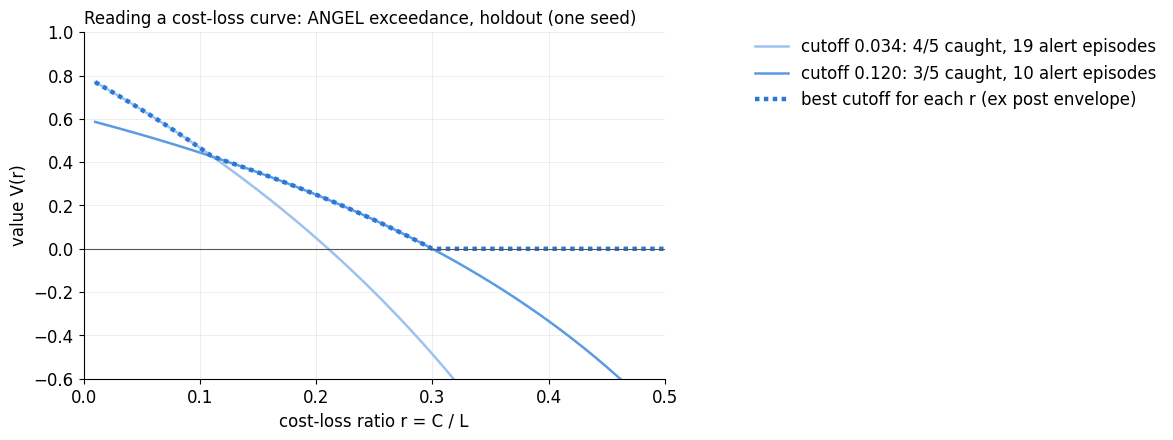

In [2]:
t = pd.read_csv(DATA / "explainer_angel_seed1000_cutoffs.csv")
Vc = np.array([V(row.D, row.A, row.N, R) for row in t.itertuples()])
env = np.maximum(Vc.max(0), 0)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
picks = sorted({int(Vc[:, list(R).index(x)].argmax()) for x in (0.02, 0.1, 0.3)}, key=lambda i: -t.A[i])
for k, i in enumerate(picks):
    row = t.iloc[i]
    ax.plot(R, Vc[i], color=["#9cc3ef", "#5a9be3", "#1f5fae"][k % 3], lw=1.8,
            label=f"cutoff {row.cutoff:.3f}: {int(row.D)}/{int(row.N)} caught, {int(row.A)} alert episodes")
ax.plot(R, env, color="#2a78d6", lw=3.2, ls=(0, (1, 1)), label="best cutoff for each r (ex post envelope)")
ax.axhline(0, color="#555555", lw=0.8)
ax.set_ylim(-0.6, 1.0); ax.set_xlim(0, 0.5)
ax.set_xlabel("cost-loss ratio r = C / L"); ax.set_ylabel("value V(r)")
ax.set_title("Reading a cost-loss curve: ANGEL exceedance, holdout (one seed)", loc="left", fontsize=12)
fig.legend(loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "01_cost_loss_explainer")

## 3. Probability quality: Brier score at 15 bp

Hourly onset label (onset within 2-24 h; hours already in a breach are excluded). Skill score against the
climatological base rate known at forecast time (CV: each fold's validation block; holdout: 2024 CV period).
*raw* = the model's own probability; *calibrated* = after the logistic recalibration used by the decision rule
(CV: fitted per fold on validation; holdout: fitted on the model's 2024 CV out-of-sample scores).
Note the forecasters' raw S_t targets a breach in 2-24 h, not an onset, so their raw Brier is slightly handicapped.

In [3]:
b = pd.read_csv(DATA / "calibrated_brier.csv")
tab = b.groupby(["model", "period"])[["brier_raw", "bss_raw", "brier_cal", "bss_cal"]].mean().unstack("period")
tab.columns = [f"{p} {m}" for m, p in tab.columns]
fam = b.drop_duplicates("model").set_index("model").family
tab.insert(0, "family", fam)
order = ["CV brier_raw", "CV bss_raw", "CV brier_cal", "CV bss_cal",
         "holdout brier_raw", "holdout bss_raw", "holdout brier_cal", "holdout bss_cal"]
tab = tab[["family"] + order].sort_values(["family", "CV bss_cal"], ascending=[False, False])
tab.round(4).to_csv(DATA / "brier_table.csv")
prev = b.groupby("period").prevalence.mean()
print(f"onset prevalence: CV {prev['CV']:.3%}, holdout {prev['holdout']:.3%}")
tab.round(4)

onset prevalence: CV 4.855%, holdout 1.015%


,family,CV brier_raw,CV bss_raw,CV brier_cal,CV bss_cal,holdout brier_raw,holdout bss_raw,holdout brier_cal,holdout bss_cal
model,,,,,,,,,
GARCH-t,forecast,0.0428,0.0780,0.0427,0.0809,0.0106,0.0789,0.0111,0.0340
ARIMA,forecast,0.5478,-10.7958,0.0436,0.0619,0.2761,-22.9671,0.0110,0.0444
TimeXer forecast,forecast,0.0494,-0.0638,0.0444,0.0438,0.0116,-0.0091,0.0102,0.1154
ANGEL exceedance,forecast,0.0465,-0.0015,0.0448,0.0361,0.0102,0.1176,0.0121,-0.0543
TiDE forecast,forecast,0.0485,-0.0447,0.0459,0.0123,0.0106,0.0795,0.0103,0.1047
TabICL,classifier,0.0612,-0.3180,0.0454,0.0214,NaN,NaN,NaN,NaN
ANGEL classifier,classifier,0.1753,-2.7742,0.0460,0.0092,NaN,NaN,NaN,NaN
Random forest,classifier,0.0644,-0.3868,0.0464,0.0011,0.0252,-1.1914,0.0107,0.0721
CatBoost,classifier,0.1511,-2.2546,0.0466,-0.0025,0.1784,-14.4850,0.0119,-0.0365


## 4. Main policy: act when the calibrated probability >= 0.1

The cutoff is fixed before the evaluation data are seen (calibration map from validation / pre-holdout data only).
The curve is the value of that single policy for every r; it peaks around the r it serves.

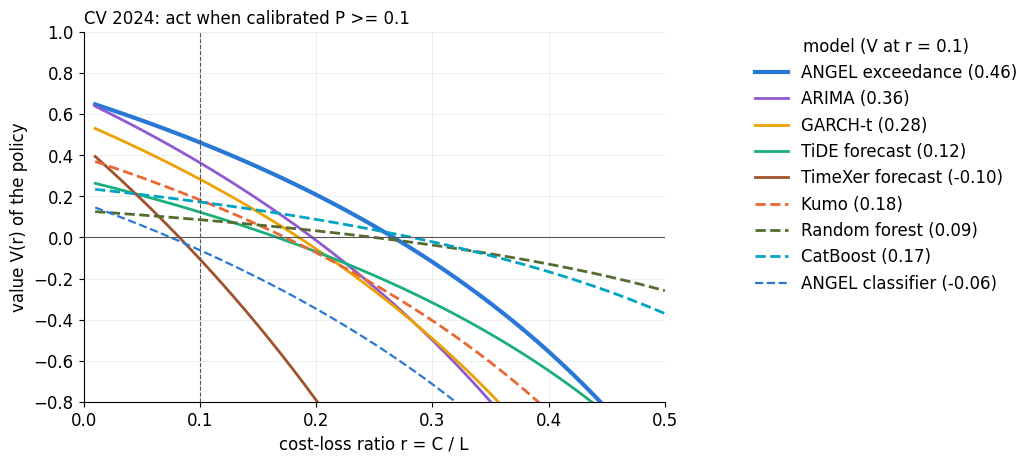

,runs,caught,events,alert_episodes,false_alerts_per_month,V(0.1),V_lead(0.1)
model,,,,,,,
ANGEL exceedance,3,12.00,18,45.00,2.75,0.46,0.22
ARIMA,1,12.00,18,61.00,4.12,0.36,0.22
|d| now,1,11.00,18,57.00,3.87,0.33,0.23
GARCH-t,1,10.00,18,54.00,3.70,0.28,0.19
Kumo,3,7.00,18,40.33,2.80,0.18,0.01
CatBoost,3,4.33,18,15.33,0.92,0.17,0.02
TiDE forecast,1,5.00,18,30.00,2.10,0.12,-0.01
Random forest,3,2.33,18,9.33,0.59,0.09,-0.01
TabICL,3,3.67,18,26.67,1.93,0.06,-0.02


In [4]:
def policy_plot(period, models, title, name, calibration="calibrated"):
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for m in models:
        v = fixed_policy_curve(period, m, 0.1, calibration)
        ax.plot(R, v, label=f"{m} ({v[list(R).index(0.1)]:.2f})", **STYLE[m])
    ax.axvline(0.1, color="#555555", lw=0.8, ls="--"); ax.axhline(0, color="#555555", lw=0.8)
    ax.set_xlim(0, 0.5); ax.set_ylim(-0.8, 1)
    ax.set_xlabel("cost-loss ratio r = C / L"); ax.set_ylabel("value V(r) of the policy")
    ax.set_title(title, loc="left", fontsize=12)
    fig.legend(title="model (V at r = 0.1)", loc="upper left", bbox_to_anchor=(1.0, 0.9))
    save(fig, name)

def policy_table(period, models, calibration="calibrated"):
    rows = []
    for m in models:
        g = runs(period, m, calibration); g = g[g.p.eq(0.1)]
        rows.append(dict(model=m, runs=len(g), caught=g.D.mean(), events=g.N.iloc[0], alert_episodes=g.A.mean(),
                         false_alerts_per_month=(g.F * HPM / g.H).mean(), **{"V(0.1)": V(g.D, g.A, g.N, 0.1).mean(),
                         "V_lead(0.1)": V_lead(g.avoided, g.perfect, g.A, g.N, 0.1).mean()}))
    return pd.DataFrame(rows).set_index("model").sort_values("V(0.1)", ascending=False).round(2)

policy_plot("CV", CV_SHOW, "CV 2024: act when calibrated P >= 0.1", "02_cv_policy_calibrated_p0p1")
policy_table("CV", CV_SHOW + ["TabICL", "|d| now"])

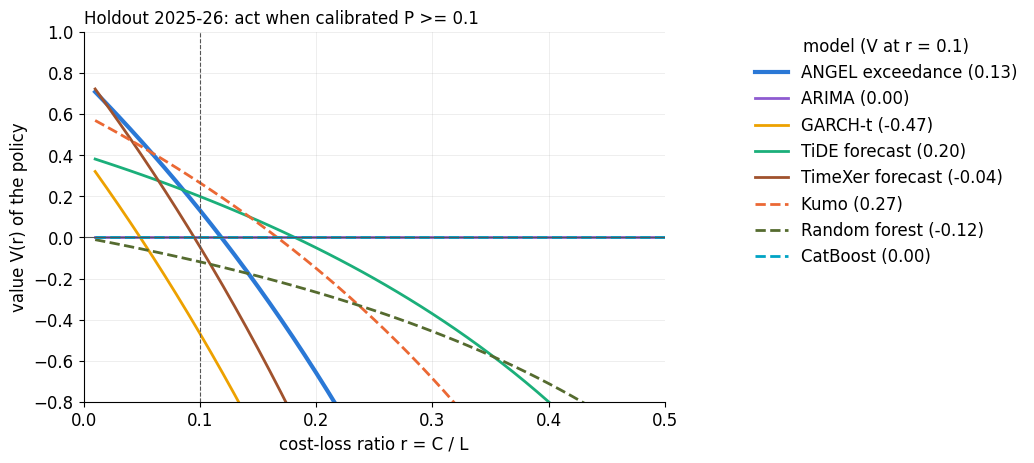

,runs,caught,events,alert_episodes,false_alerts_per_month,V(0.1),V_lead(0.1)
model,,,,,,,
Kumo,1,3.00,5,18.00,0.96,0.27,0.16
TiDE forecast,1,2.00,5,11.00,0.58,0.20,0.08
ANGEL exceedance,6,3.83,5,32.33,1.83,0.13,-0.12
CatBoost,3,0.00,5,0.00,0.00,0.00,0.00
ARIMA,1,0.00,5,0.00,0.00,0.00,0.00
TimeXer forecast,1,4.00,5,42.00,2.44,-0.04,-0.16
Random forest,3,0.00,5,5.33,0.34,-0.12,-0.12
|d| now,1,3.00,5,40.00,2.38,-0.22,-0.27
GARCH-t,1,2.00,5,41.00,2.51,-0.47,-0.50


In [5]:
policy_plot("holdout", HO_SHOW, "Holdout 2025-26: act when calibrated P >= 0.1", "03_holdout_policy_calibrated_p0p1")
policy_table("holdout", HO_SHOW + ["|d| now"])

**Base-rate shift.** The onset rate is ~5x lower on the holdout than in 2024, so a calibration map fitted on 2024
over-states holdout probabilities (more alerts). The forecasters' raw probabilities are conditional on the current
state and need no map; the same rule on the **raw** probability (no recalibration) for comparison:

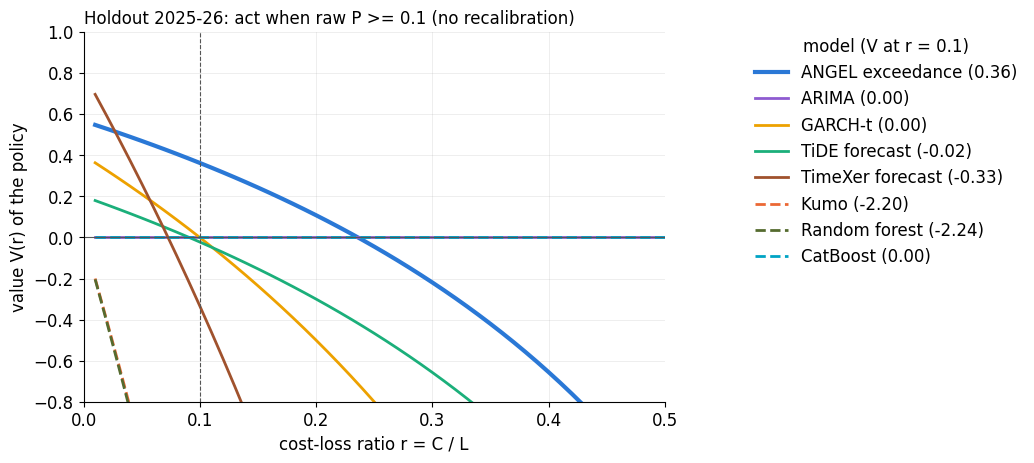

,runs,caught,events,alert_episodes,false_alerts_per_month,V(0.1),V_lead(0.1)
model,,,,,,,
ANGEL exceedance,6,2.83,5,12.0,0.59,0.36,0.08
ARIMA,1,0.00,5,0.0,0.00,0.00,0.00
GARCH-t,1,2.00,5,20.0,1.16,0.00,-0.01
CatBoost,3,0.00,5,0.0,0.00,0.00,0.00
TiDE forecast,1,1.00,5,11.0,0.64,-0.02,-0.09
TimeXer forecast,1,4.00,5,55.0,3.28,-0.33,-0.50
Kumo,1,0.00,5,99.0,6.36,-2.20,-2.20
Random forest,3,0.00,5,101.0,6.49,-2.24,-2.24


In [6]:
policy_plot("holdout", HO_SHOW, "Holdout 2025-26: act when raw P >= 0.1 (no recalibration)", "04_holdout_policy_raw_p0p1", "raw")
policy_table("holdout", HO_SHOW, "raw")

## 5. Threshold-free summary: decision curves on the raw probabilities

Each user acts on its own cost-loss ratio and uses the forecast **as a probability**: act when P >= r. V(r) of that
rule, plotted against r, is the **decision curve** (standardised net benefit, section 2). Nothing is fitted — no
cutoff, no calibration map — so the curve cannot overfit one period, and it rewards probabilities that mean what
they say.

**Summary: weighted area under the net-benefit curve** (WA-NBC, Talluri & Shete 2016): sum of V(r) f(r) over
r in [0.01, 0.5], with f normalised on that range; f is the distribution of users' cost-loss ratios. With f uniform
it is the decision-rule analogue of AUVC; Hand (2009) makes the same point for AUC and proposes Beta(2, 2) as a
neutral default. **Headline f: the LP prior** of section 5a, estimated from the LP backtest's economics before the
holdout; Beta(2, 18) and Hand's Beta(2, 2) are reported for comparison.

**Which probability.** Each model enters with the probability a user could deploy before the test data: the
forecasters' **raw** exceedance probability, the direct classifiers' **Platt-calibrated** probability (logistic map
on logit(score), fitted on validation / 2024 CV data; their raw outputs come from class-weighted training or the 2024
base rate and are not probabilities of the evaluated event). The second table gives raw and Platt for every model:
the map helps the classifiers in CV, but fitted on 2024 it over-states holdout probabilities after the ~5x drop in
the onset rate, and it hurts every forecaster, whose raw probability conditions on the current state. Cutoffs tuned
on validation do not transfer either (section 5b: ARIMA is best in CV with tuned cutoffs and worth nothing on the
holdout). The rule only pays for small r: for large r it waits for P >= 0.3-0.5, reached only once the move is under
way, so Hand's Beta(2, 2) area is negative for every score.

**Headline table:** WA-NBC under the LP prior and under its GPD-tail variant (section 5a; same costs, tail-fitted
expected loss), [min, max] over seeds.

Band: range over ANGEL seeds (3 in CV, 6 on the holdout). |d| now is not a probability and has no decision curve.


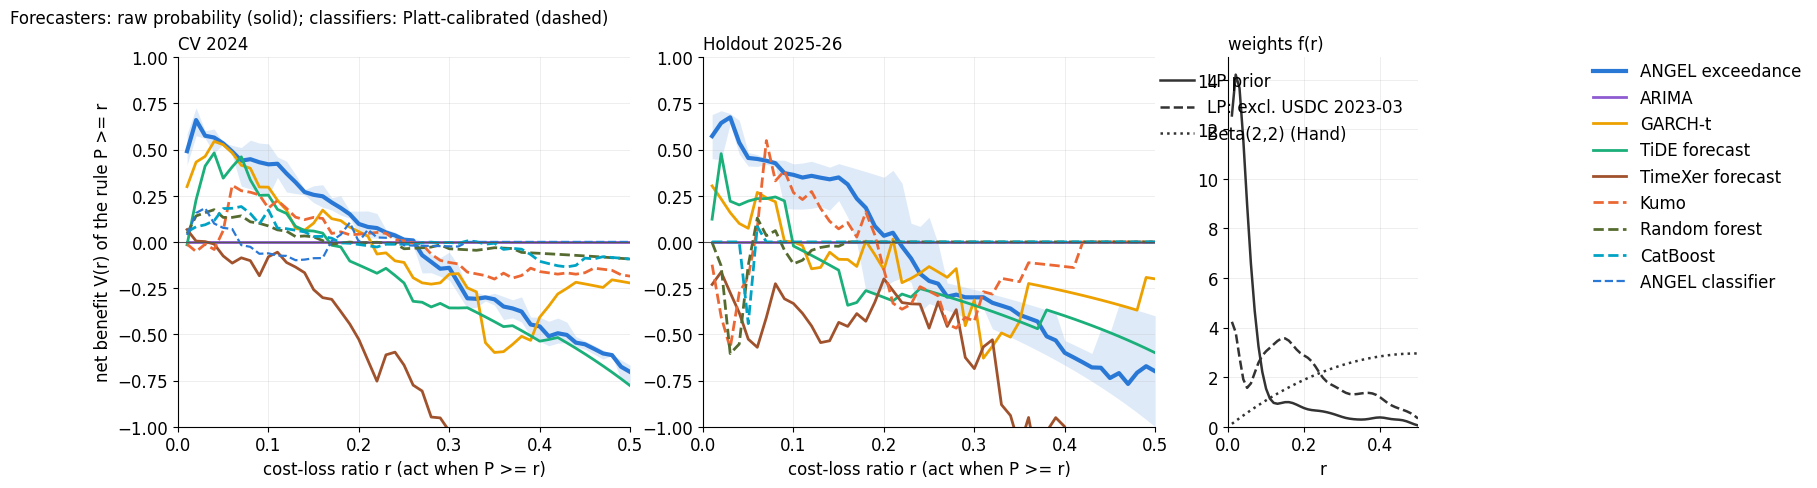

,probability,LP prior CV,LP prior holdout,LP: GPD tail CV,LP: GPD tail holdout
model,,,,,
ANGEL exceedance,raw,"0.430 [0.41, 0.44]","0.422 [0.39, 0.44]","0.442 [0.44, 0.45]","0.451 [0.39, 0.49]"
TiDE forecast,raw,0.203,0.136,0.144,0.145
GARCH-t,raw,0.332,0.108,0.309,0.129
ARIMA,raw,0.000,0.000,0.000,0.000
CatBoost,Platt,"0.090 [0.06, 0.11]","-0.034 [-0.05, 0.00]","0.071 [0.03, 0.10]","-0.016 [-0.03, 0.00]"
Kumo,Platt,"0.042 [0.00, 0.08]",-0.162,"0.000 [-0.02, 0.01]",-0.232
Random forest,Platt,"0.099 [0.07, 0.13]","-0.170 [-0.21, -0.10]","0.090 [0.06, 0.13]","-0.172 [-0.23, -0.10]"
TimeXer forecast,raw,-0.162,-0.384,-0.139,-0.340
ANGEL classifier,Platt,0.067,NaN,0.078,NaN


,CV WA-NBC LP prior,holdout WA-NBC LP prior,CV WA-NBC LP: GPD tail,holdout WA-NBC LP: GPD tail,CV WA-NBC LP: excl. USDC 2023-03,holdout WA-NBC LP: excl. USDC 2023-03,CV WA-NBC LP: per event,holdout WA-NBC LP: per event,"CV WA-NBC Beta(2,18)","holdout WA-NBC Beta(2,18)","CV WA-NBC Beta(2,2) (Hand)","holdout WA-NBC Beta(2,2) (Hand)",CV V(0.1),holdout V(0.1)
model,,,,,,,,,,,,,,
ANGEL exceedance,0.430,0.422,0.442,0.451,0.135,0.086,0.233,0.199,0.395,0.376,-0.203,-0.296,0.420,0.363
TiDE forecast,0.203,0.136,0.144,0.145,-0.062,-0.155,0.023,-0.039,0.210,0.056,-0.338,-0.345,0.253,-0.022
GARCH-t,0.332,0.108,0.309,0.129,0.045,-0.094,0.158,-0.022,0.290,0.050,-0.182,-0.241,0.296,0.000
ARIMA,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
CatBoost,0.090,-0.034,0.071,-0.016,0.029,-0.005,0.052,-0.016,0.097,-0.026,-0.028,-0.002,0.173,0.000
Kumo,0.042,-0.162,0.000,-0.232,0.031,-0.064,0.025,-0.113,0.125,0.034,-0.071,-0.110,0.183,0.267
Random forest,0.099,-0.170,0.090,-0.172,0.023,-0.042,0.051,-0.094,0.085,-0.094,-0.030,-0.008,0.086,-0.119
TimeXer forecast,-0.162,-0.384,-0.139,-0.340,-0.517,-0.528,-0.412,-0.504,-0.169,-0.389,-1.003,-0.879,-0.080,-0.333
ANGEL classifier,0.067,NaN,0.078,NaN,0.000,NaN,0.028,NaN,0.010,NaN,-0.004,NaN,-0.062,NaN


In [7]:
from scipy.stats import beta as Beta
# cost-loss priors on the r grid: LP economics (section 5a, slides/compute_cost_loss_prior.py) and generic Betas
lp = pd.read_csv(DATA / "cost_loss_weights.csv", index_col=0)
assert np.allclose(lp.index.to_numpy(), R)
WEIGHTS = {"LP prior": lp["sample mean"].to_numpy(), "LP: GPD tail": lp["GPD tail"].to_numpy(),
           "LP: excl. USDC 2023-03": lp["excl. USDC 2023-03"].to_numpy(), "LP: per event": lp["per event"].to_numpy(),
           "Beta(2,18)": Beta(2, 18).pdf(R), "Beta(2,2) (Hand)": Beta(2, 2).pdf(R)}
WEIGHTS = {k: w / w.sum() for k, w in WEIGHTS.items()}          # normalised on r in [0.01, 0.5]
SHOW_W = {"LP prior": "-", "LP: excl. USDC 2023-03": "--", "Beta(2,2) (Hand)": ":"}

FAMILY = grid.drop_duplicates("model").set_index("model").family
def headline_cal(model):
    """Forecasters: raw exceedance probability; direct classifiers: Platt-calibrated (map fitted before the test data)."""
    return "calibrated" if FAMILY[model] == "classifier" else "raw"

def dca_runs(period, model, cal=None):
    """Decision curve of every run: act when P >= r, valued at r (runs x r)."""
    out = []
    for _, g in runs(period, model, cal or headline_cal(model)).groupby("run"):
        g = g.set_index("p").loc[R]
        out.append(V(g.D, g.A, g.N, R).to_numpy())
    return np.array(out)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 0.42]))
rows = []
for ax, period, models in zip(axes[:2], ("CV", "holdout"), (CV_SHOW, HO_SHOW)):
    for m in models:
        c = dca_runs(period, m)
        if not len(c):
            continue
        wa = {k: c @ w for k, w in WEIGHTS.items()}
        rows.append(dict(period=period, model=m, probability="Platt" if headline_cal(m) == "calibrated" else "raw",
                         runs=len(c), **{f"WA-NBC {k}": v.mean() for k, v in wa.items()},
                         **{f"{k} min": wa[k].min() for k in ("LP prior", "LP: GPD tail")},
                         **{f"{k} max": wa[k].max() for k in ("LP prior", "LP: GPD tail")},
                         **{"V(0.1)": c[:, list(R).index(0.1)].mean()}))
        ax.plot(R, c.mean(0), label=m if period == "CV" else None, **STYLE[m])
        if m == "ANGEL exceedance":
            ax.fill_between(R, c.min(0), c.max(0), color=STYLE[m]["color"], alpha=0.15, lw=0)
    ax.axhline(0, color="#555555", lw=0.8); ax.set_xlim(0, 0.5); ax.set_ylim(-1, 1)
    ax.set_xlabel("cost-loss ratio r (act when P >= r)")
    ax.set_title("CV 2024" if period == "CV" else "Holdout 2025-26", loc="left", fontsize=12)
axes[0].set_ylabel("net benefit V(r) of the rule P >= r")
fig.suptitle("Forecasters: raw probability (solid); classifiers: Platt-calibrated (dashed)", x=0.02, ha="left", fontsize=12)
axes[1].sharey(axes[0])
for k, ls in SHOW_W.items():
    axes[2].plot(R, WEIGHTS[k] / (R[1] - R[0]), color="#333333", ls=ls, lw=1.8, label=k)
axes[2].set_xlim(0, 0.5); axes[2].set_ylim(bottom=0); axes[2].set_xlabel("r")
axes[2].set_title("weights f(r)", loc="left", fontsize=12); axes[2].legend(loc="upper right")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "05_decision_curves")
dca = pd.DataFrame(rows)
# headline table: WA-NBC under the LP prior and its GPD-tail variant; range over seeds where a model has several runs
def cell(r, k):
    v, lo, hi = r[f"WA-NBC {k}"], r[f"{k} min"], r[f"{k} max"]
    return f"{v:.3f}" + (f" [{lo:.2f}, {hi:.2f}]" if r.runs > 1 else "")
head = dca.assign(**{k: dca.apply(cell, axis=1, k=k) for k in ("LP prior", "LP: GPD tail")}) \
          .pivot(index="model", columns="period", values=["LP prior", "LP: GPD tail"])
head.columns = [f"{k} {p}" for k, p in head.columns]
head.insert(0, "probability", dca.drop_duplicates("model").set_index("model").probability)
order = dca[dca.period.eq("holdout")].set_index("model")["WA-NBC LP prior"].sort_values(ascending=False).index
head = head.loc[list(order) + [m for m in head.index if m not in order]]
head.to_csv(DATA / "wanbc_headline.csv")
display(head)
# all weightings (sensitivity), same probabilities
wanbc = dca.pivot(index="model", columns="period", values=[f"WA-NBC {k}" for k in WEIGHTS] + ["V(0.1)"])
wanbc.columns = [f"{p} {k}" for k, p in wanbc.columns]
wanbc = wanbc.loc[head.index]
wanbc.round(3)


In [8]:
# raw vs Platt for every model under the LP prior: recalibration helps the classifiers in CV, but the 2024 map
# over-states holdout probabilities after the drop in the onset rate and hurts every forecaster
rp = []
for period, models in (("CV", CV_SHOW), ("holdout", HO_SHOW)):
    for m in models:
        for cal, lab in (("raw", "raw"), ("calibrated", "Platt")):
            c = dca_runs(period, m, cal)
            if len(c):
                rp.append(dict(model=m, col=f"{period} {lab}", v=(c @ WEIGHTS["LP prior"]).mean()))
rp = pd.DataFrame(rp).pivot(index="model", columns="col", values="v")
rp[["CV raw", "CV Platt", "holdout raw", "holdout Platt"]].loc[head.index].round(3)


col,CV raw,CV Platt,holdout raw,holdout Platt
model,,,,
ANGEL exceedance,0.430,0.259,0.422,-0.217
TiDE forecast,0.203,0.087,0.136,-0.090
GARCH-t,0.332,0.158,0.108,-0.308
ARIMA,0.000,0.231,0.000,-0.001
CatBoost,-0.075,0.090,-0.236,-0.034
Kumo,-0.073,0.042,-0.498,-0.162
Random forest,-0.083,0.099,-0.513,-0.170
TimeXer forecast,-0.162,-0.023,-0.384,-0.380
ANGEL classifier,-0.137,0.067,NaN,NaN


### 5a. The cost-loss prior from LP economics

f(r) is the distribution of cost-loss ratios r = C / E[L] across users, so it is estimated from the economics of the
action, not chosen (`slides/compute_cost_loss_prior.py`, on the LP backtest simulator of onchain-insights/14; only
data before the holdout). A user runs the Gamma-style vault on the USDC/USDT 0.01% pool and exits to 50/50 for an
alert episode; PnL is the backtest's hedged PnL (fees + LVR - gas - swap costs), bp of the vault.

* **C**, cost of acting on a false alert: PnL lost by exiting for an episode with no event (fees forgone, burn/mint
  gas and swaps, minus LVR avoided); 150 placebo episodes in quiet hours, 2024-03-20 to the holdout.
* **L_e**, loss a perfect warning avoids on event e: PnL gained by exiting from 24 h before the onset to the end of
  the breach, plus C; the 35 pool 15 bp onsets from 2022-05 to the holdout. Fees are not observed before 2024-03-19
  and are imputed for earlier events with the vault's mean fee rate in observed event windows.
* **Users**: vault size {100k, 1M, 5M} x costs {low, base, high} (the backtest's sensitivity grid), equally weighted.
* **E[L]** (headline): sample mean of L_e, bootstrapped over events. Sensitivity: a GPD tail (the fitted shape is
  > 1 for every user, so E[L] is infinite and r = 0: acting always pays), the mean without USDC in March 2023, and
  per-event ratios C / L_e (the typical event rather than the expectation).

**Reading.** Typical 15 bp events are *not* worth exiting for: in 2024 the depeg's fee surge exceeds the losses avoided
(median L_e < 0 for vaults <= 1M). The expected loss is carried by the tail (FTX 2022-11, USDC 2023-03): with it,
r = C / E[L] is 0.02-0.07 for every user, so the prior sits at small r. Without the USDC event, r is 0.1-0.3 for the 5M vault
(and 1M at high costs) and above 0.7, or acting never pays, for the smaller vaults. The prior is therefore a statement about tail risk, and the WA-NBC under it is
reported with the without-USDC version beside it.


C (bp)  median L_e     E[L]  E[L] excl. USDC  GPD shape  \
V0   cost                                                            
0.1M low    4.721     -12.630   66.961           -5.144      1.693   
     base   3.646      -6.372   78.111            2.079      1.481   
     high  -0.309      11.702  124.045           31.268      1.354   
1M   low    4.018      -4.309   75.816            2.720      1.517   
     base   3.591      -2.215   79.134            4.998      1.474   
     high   2.876       0.455   85.927            9.470      1.435   
5M   low    2.243       2.347   85.337           10.625      1.690   
     base   1.874       2.921   87.958           12.460      1.914   
     high   1.448       4.479   91.269           14.733      1.622   

           r = C/E[L]  r excl. USDC  
V0   cost                            
0.1M low        0.071           inf  
     base       0.047         1.753  
     high      -0.002        -0.010  
1M   low        0.053         1.477  
     base       0.045         0.719  
     high       0.033         0.304  
5M   low        0.026         0.211  
     base       0.021         0.150  
     high       0.016         0.098

,share_never,share_r_lt_0p01,share_r_gt_0p5,median_r,mean_r_in_grid
prior,,,,,
sample mean,0.073,0.163,0.075,0.034,0.081
GPD tail,0.058,0.713,0.058,0.000,0.072
excl. USDC 2023-03,0.188,0.111,0.238,0.237,0.193
per event,0.479,0.111,0.143,0.175,0.155


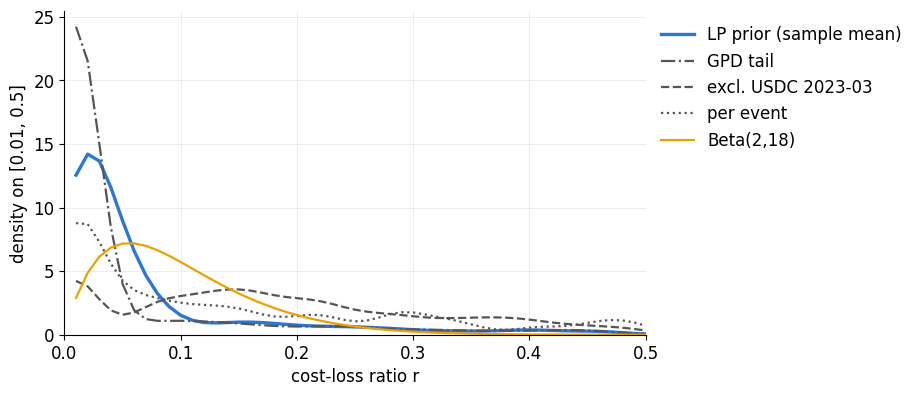

In [9]:
users = pd.read_csv(DATA / "cost_loss_users.csv")
users["V0"] = users.V0.map(lambda v: f"{v / 1e6:g}M")
display(users.set_index(["V0", "cost"])[["C_bp", "L_median", "L_mean", "L_mean_excl", "gpd_xi", "r_mean", "r_mean_excl"]]
        .rename(columns={"C_bp": "C (bp)", "L_median": "median L_e", "L_mean": "E[L]", "L_mean_excl": "E[L] excl. USDC",
                         "gpd_xi": "GPD shape", "r_mean": "r = C/E[L]", "r_mean_excl": "r excl. USDC"}).round(3))
pr = pd.read_csv(DATA / "cost_loss_prior.csv").set_index("prior")
display(pr[["share_never", "share_r_lt_0p01", "share_r_gt_0p5", "median_r", "mean_r_in_grid"]].round(3))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for k, ls in zip(["sample mean", "GPD tail", "excl. USDC 2023-03", "per event"], ("-", "-.", "--", ":")):
    ax.plot(R, lp[k] / lp[k].sum() / (R[1] - R[0]), color="#2a78d6" if k == "sample mean" else "#555555", ls=ls,
            lw=2.4 if k == "sample mean" else 1.6, label="LP prior (sample mean)" if k == "sample mean" else k)
ax.plot(R, Beta(2, 18).pdf(R) / Beta(2, 18).pdf(R).sum() / (R[1] - R[0]), color="#eda100", lw=1.6, label="Beta(2,18)")
ax.set_xlim(0, 0.5); ax.set_ylim(bottom=0); ax.set_xlabel("cost-loss ratio r"); ax.set_ylabel("density on [0.01, 0.5]")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
save(fig, "05a_cost_loss_prior")


### 5b. Why not tune the cutoff on validation?

For every r, choose the cutoff p on data the evaluation never sees (CV: each fold's validation block; holdout: the
model's 2024 CV results), apply it and score at r; the mean over r is a "deployable AUVC". It is honest but fragile:
the cutoff that was best in one period is not the best in the next. The table compares how each summary carries
over from CV to the holdout.


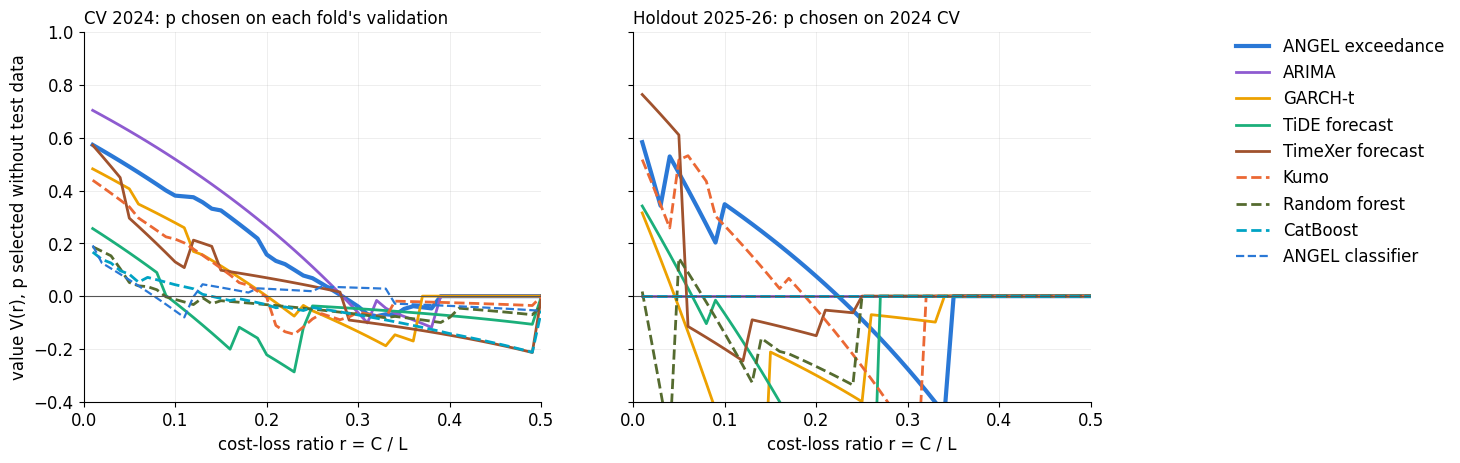

ex post AUVC         validation-selected          \
                           CV holdout                  CV holdout   
model                                                               
ANGEL exceedance        0.227   0.212               0.156   0.067   
TiDE forecast           0.117   0.084              -0.052  -0.164   
GARCH-t                 0.158   0.103               0.062  -0.164   
ARIMA                   0.246   0.133               0.205   0.000   
CatBoost                0.080     NaN              -0.049   0.000   
Kumo                    0.173   0.178               0.051   0.022   
Random forest           0.096     NaN              -0.028  -0.092   
TimeXer forecast        0.095   0.147               0.036   0.020   
ANGEL classifier        0.038     NaN               0.007     NaN   
|d| now                   NaN   0.145               0.108  -0.083   

                 DCA WA-NBC LP prior          
                                  CV holdout  
model                                         
ANGEL exceedance               0.430   0.422  
TiDE forecast                  0.203   0.136  
GARCH-t                        0.332   0.108  
ARIMA                          0.000   0.000  
CatBoost                       0.090  -0.034  
Kumo                           0.042  -0.162  
Random forest                  0.099  -0.170  
TimeXer forecast              -0.162  -0.384  
ANGEL classifier               0.067     NaN  
|d| now                          NaN     NaN

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
rows = []
for ax, period, models in zip(axes, ("CV", "holdout"), (CV_SHOW, HO_SHOW)):
    for m in models + ["|d| now"]:
        v = selected_curve(period, m)
        rows.append(dict(period=period, model=m, deployable_AUVC=v.mean()))
        if m != "|d| now":
            ax.plot(R, v, label=m if period == "CV" else None, **STYLE[m])
    ax.axhline(0, color="#555555", lw=0.8); ax.set_xlim(0, 0.5); ax.set_ylim(-0.4, 1)
    ax.set_xlabel("cost-loss ratio r = C / L")
    ax.set_title("CV 2024: p chosen on each fold's validation" if period == "CV"
                 else "Holdout 2025-26: p chosen on 2024 CV", loc="left", fontsize=12)
axes[0].set_ylabel("value V(r), p selected without test data")
fig.legend(loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "05b_validation_selected_envelopes")
dep = pd.DataFrame(rows).pivot(index="model", columns="period", values="deployable_AUVC")
auvc = pd.concat([pd.read_csv(DATA / "cv_summary.csv").set_index("model").AUVC.rename("CV"),
                  pd.read_csv(DATA / "holdout_summary.csv").set_index("model").AUVC.rename("holdout")], axis=1)
stab = pd.concat({"ex post AUVC": auvc, "validation-selected": dep,
                  "DCA WA-NBC LP prior": wanbc[["CV WA-NBC LP prior", "holdout WA-NBC LP prior"]]
                                           .set_axis(["CV", "holdout"], axis=1)}, axis=1).reindex(dep.index)
stab.sort_values(("DCA WA-NBC LP prior", "holdout"), ascending=False).round(3)


**Value heatmap.** Rows: the probability threshold p the user acts on; columns: the user's true cost-loss ratio
r. Blue = positive value, red = worse than never acting. The diagonal p = r is the decision rule; for a calibrated
score whose P were the probability that acting pays off, the best row for each column would sit on it; here it
does so only for small r (section 5).

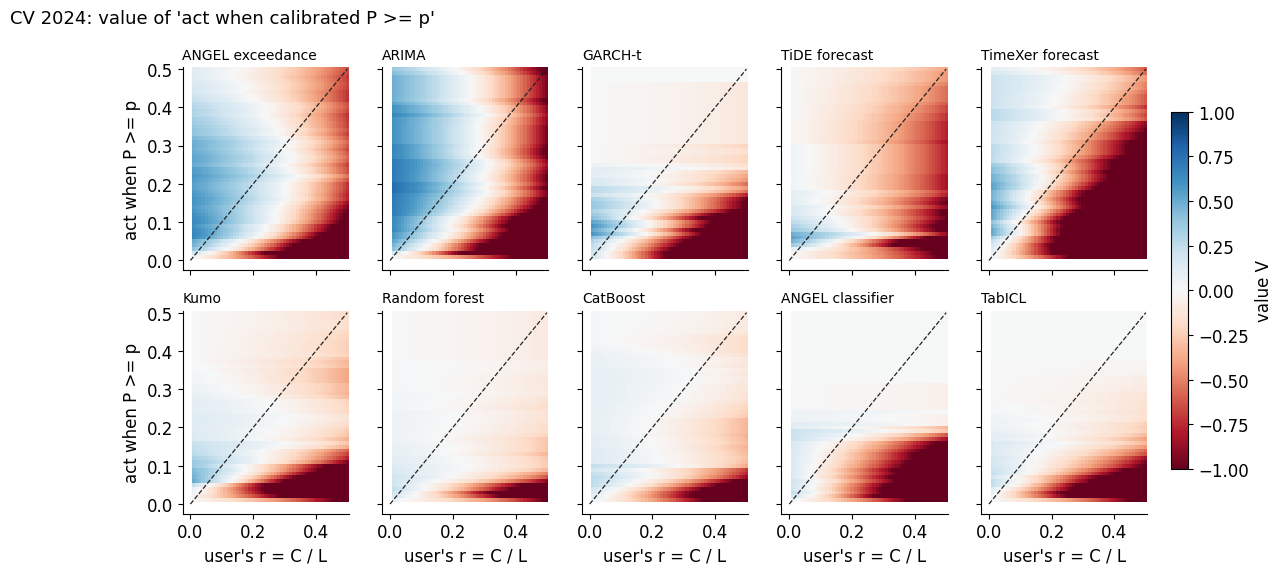

In [11]:
from matplotlib.colors import TwoSlopeNorm
def heatmaps(period, models, name):
    n = len(models); ncol = 5 if n > 8 else 4; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.0 * ncol, 2.9 * nrow), sharex=True, sharey=True)
    norm = TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
    for ax, m in zip(axes.flat, models):
        M = []
        for _, g in runs(period, m).groupby("run"):
            g = g.set_index("p").loc[R]
            M.append(np.array([V(g.D.values, g.A.values, g.N.values, r) for r in R]).T)   # p x r
        im = ax.pcolormesh(R, R, np.clip(np.mean(M, 0), -1, 1), cmap="RdBu", norm=norm, shading="nearest")
        ax.plot([0, 0.5], [0, 0.5], color="#222222", lw=0.9, ls="--")
        ax.set_title(m, fontsize=10, loc="left"); ax.grid(False)
    for ax in axes.flat[n:]:
        ax.axis("off")
    for ax in axes[-1]: ax.set_xlabel("user's r = C / L")
    for ax in axes[:, 0]: ax.set_ylabel("act when P >= p")
    cb = fig.colorbar(im, ax=axes, location="right", shrink=0.8, pad=0.02); cb.set_label("value V")
    fig.suptitle(f"{'CV 2024' if period == 'CV' else 'Holdout 2025-26'}: value of 'act when calibrated P >= p'",
                 x=0.01, ha="left", fontsize=13)
    save(fig, name)

heatmaps("CV", CV_SHOW + ["TabICL"], "06_cv_value_heatmaps")

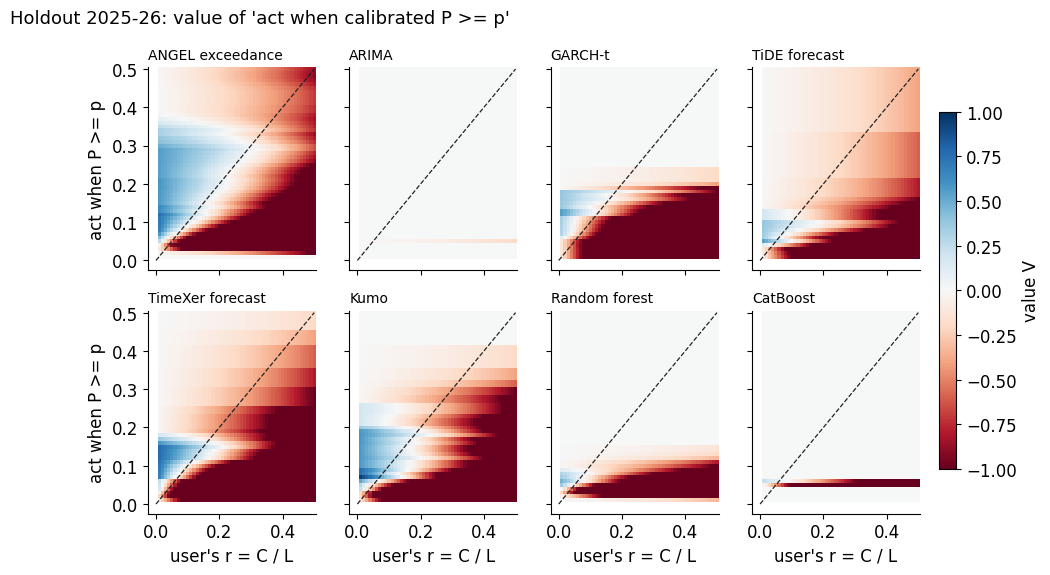

In [12]:
heatmaps("holdout", HO_SHOW, "07_holdout_value_heatmaps")

## 6. Cost-loss is a simplification: lead time

Standard V(r) counts a caught event as fully avoided whether the warning came 23 h or 2 h before onset. The
lead-time-aware value measures the loss a warning at t_a avoids as the move still ahead,
L_e(t_a) = max_{onset <= t <= onset + 24 h} |d_t| - |d_{t_a}| (bp, >= 0); a perfect warning comes 24 h before onset.
The **cost per alert episode C (bp) stays fixed**, so the x-axis is C in bp (C = r x mean perfect loss). For each
C the threshold p is chosen without the evaluation data (as in section 5), maximising the lead-time-aware value.
Includes the current-deviation baseline |d| (calibrated the same way).

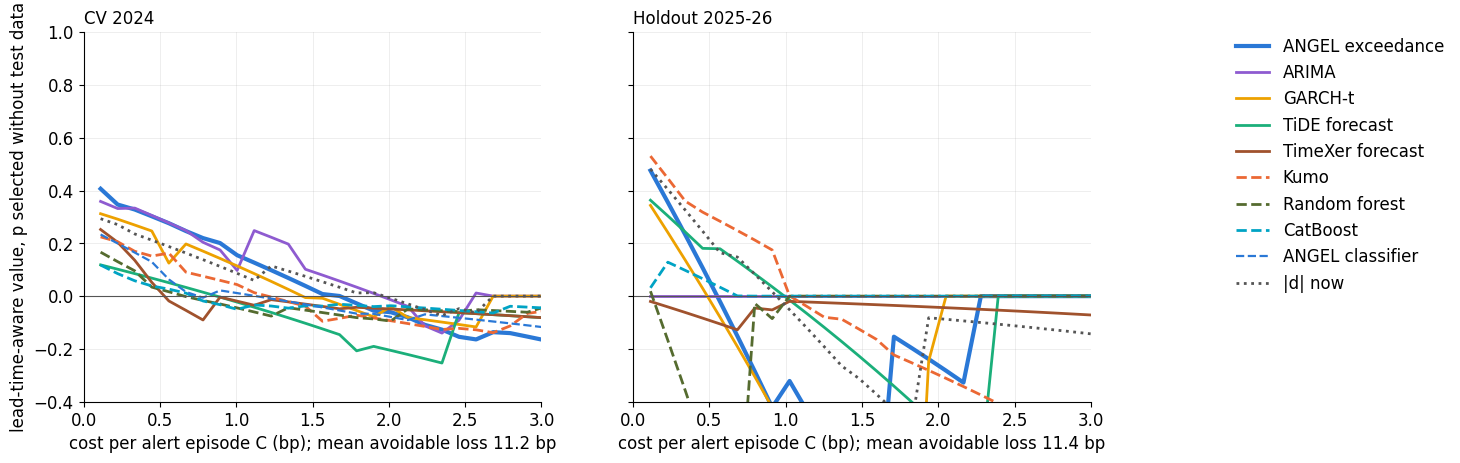

deployable_AUVC         deployable_AUVC_lead        
period                        CV holdout                   CV holdout
model                                                                
ANGEL classifier           0.007     NaN               -0.021     NaN
ANGEL exceedance           0.156   0.067                0.022  -0.092
ARIMA                      0.205   0.000                0.058   0.000
CatBoost                  -0.049   0.000               -0.034   0.007
GARCH-t                    0.062  -0.164                0.027  -0.168
Kumo                       0.051   0.022               -0.006  -0.158
Random forest             -0.028  -0.092               -0.028  -0.057
TiDE forecast             -0.052  -0.164               -0.049  -0.046
TimeXer forecast           0.036   0.020               -0.031  -0.028
|d| now                    0.108  -0.083                0.038  -0.058

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
rows = []
for ax, period, models in zip(axes, ("CV", "holdout"), (CV_SHOW, HO_SHOW)):
    g0 = runs(period, "ANGEL exceedance"); L_bar = (g0.perfect / g0.N).mean()
    for m in models + ["|d| now"]:
        v = selected_curve(period, m, lead=True); st = selected_curve(period, m)
        rows.append(dict(period=period, model=m, deployable_AUVC=st.mean(), deployable_AUVC_lead=v.mean()))
        ax.plot(R * L_bar, v, label=m if period == "CV" else None, **STYLE[m])
    ax.axhline(0, color="#555555", lw=0.8); ax.set_xlim(0, 3); ax.set_ylim(-0.4, 1)
    ax.set_xlabel(f"cost per alert episode C (bp); mean avoidable loss {L_bar:.1f} bp")
    ax.set_title("CV 2024" if period == "CV" else "Holdout 2025-26", loc="left", fontsize=12)
axes[0].set_ylabel("lead-time-aware value, p selected without test data")
fig.legend(loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "08_lead_time_value")
pd.DataFrame(rows).pivot(index="model", columns="period").round(3)

## Appendix C: the decision rule on the recalibrated probability (diagonal of the heatmaps)

Same rule as section 5, applied after the 2024 calibration map: worse on the holdout, where the map over-states
probabilities after the drop in the onset rate.


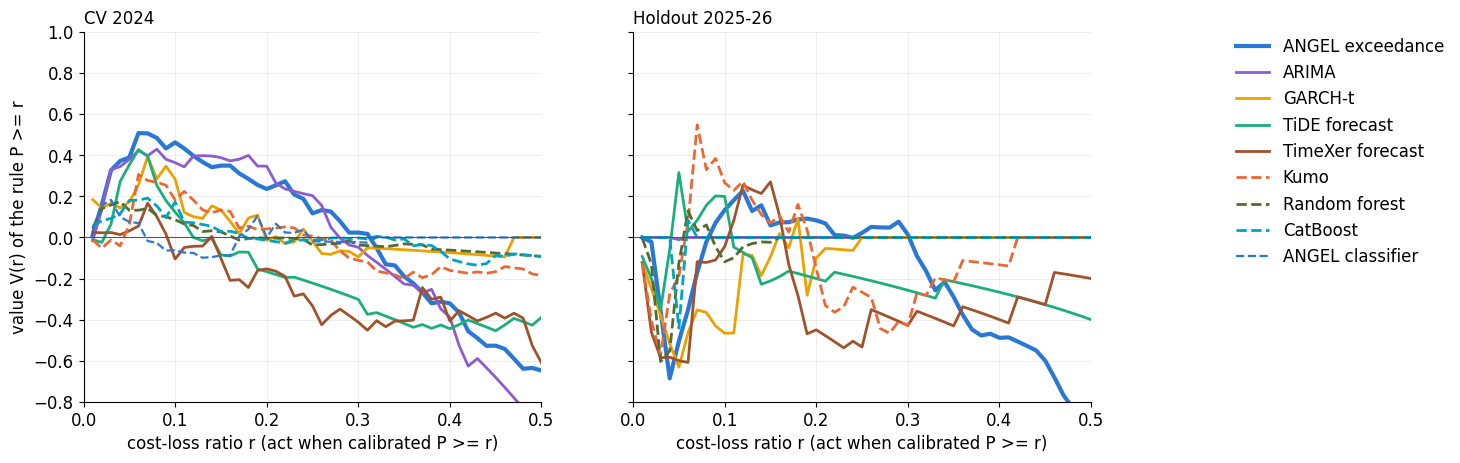

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, period, models in zip(axes, ("CV", "holdout"), (CV_SHOW, HO_SHOW)):
    for m in models:
        ax.plot(R, rule_curve(period, m), label=m if period == "CV" else None, **STYLE[m])
    ax.axhline(0, color="#555555", lw=0.8); ax.set_xlim(0, 0.5); ax.set_ylim(-0.8, 1)
    ax.set_xlabel("cost-loss ratio r (act when calibrated P >= r)")
    ax.set_title("CV 2024" if period == "CV" else "Holdout 2025-26", loc="left", fontsize=12)
axes[0].set_ylabel("value V(r) of the rule P >= r")
fig.legend(loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "C1_rule_curves_diagonal")

## Appendix A: ex post AUVC (ranking only)

Best cutoff for every r chosen on the evaluation data itself: measures how well a score *ranks* hours, independent
of calibration. Kept for reference; the deployable comparison is sections 4-6.

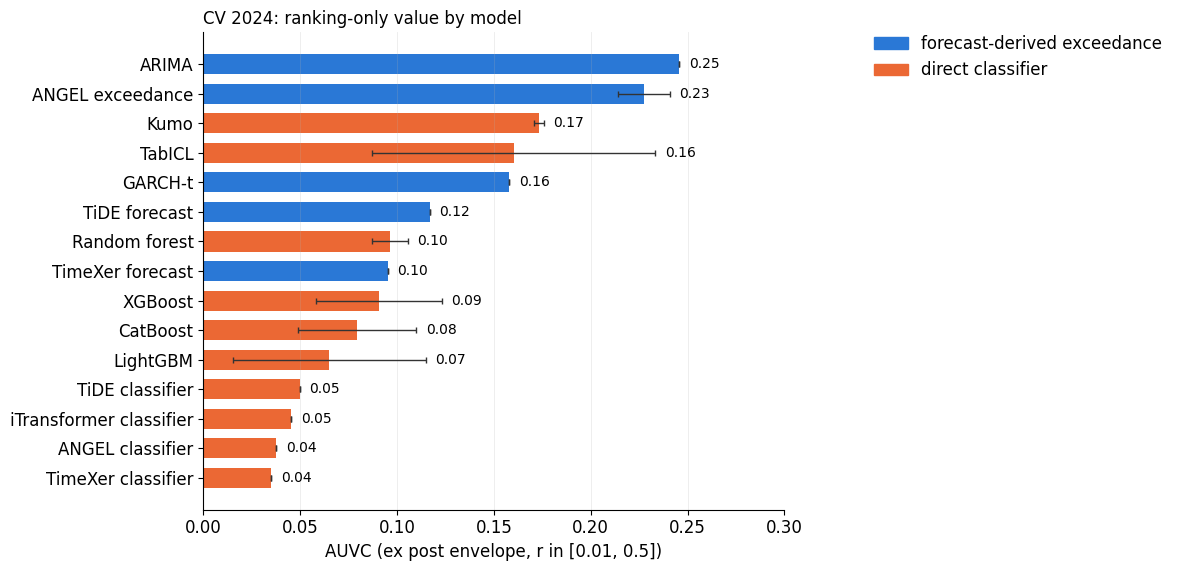

In [15]:
cv = pd.read_csv(DATA / "cv_summary.csv").sort_values("AUVC")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
y = np.arange(len(cv))
ax.barh(y, cv.AUVC, color=[FAMILY_COLOR[f] for f in cv.family], height=0.68, edgecolor="none")
ax.errorbar(cv.AUVC, y, xerr=cv.AUVC_sd.fillna(0), fmt="none", ecolor="#333333", elinewidth=1, capsize=2)
for yi, v, sd in zip(y, cv.AUVC, cv.AUVC_sd.fillna(0)):
    ax.text(v + sd + 0.005, yi, f"{v:.2f}", va="center", fontsize=10)
ax.set_yticks(y); ax.set_yticklabels(cv.model); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUVC (ex post envelope, r in [0.01, 0.5])"); ax.set_xlim(0, 0.3)
ax.set_title("CV 2024: ranking-only value by model", loc="left", fontsize=12)
fig.legend(handles=[Patch(color=FAMILY_COLOR["forecast"], label="forecast-derived exceedance"),
                    Patch(color=FAMILY_COLOR["classifier"], label="direct classifier")],
           loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "A1_cv_auvc_ex_post")

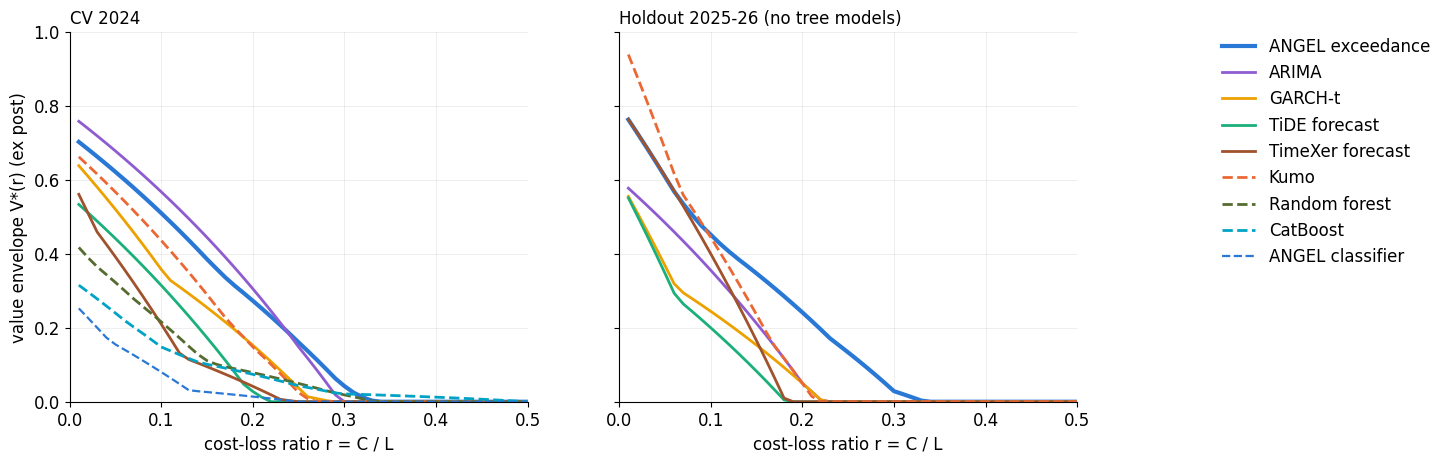

In [16]:
cc = pd.read_csv(DATA / "cv_curves.csv"); hc = pd.read_csv(DATA / "holdout_curves.csv")
cs = pd.read_csv(DATA / "cv_summary.csv").set_index("model"); hs = pd.read_csv(DATA / "holdout_summary.csv").set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (df, summ, period) in zip(axes, ((cc, cs, "CV"), (hc[hc.kind.eq("standard")], hs, "holdout"))):
    for m in (CV_SHOW if period == "CV" else HO_SHOW):
        g = df[df.model.eq(m)]
        if len(g):
            ax.plot(g.r, g.V, label=m if period == "CV" else None, **STYLE[m])
    ax.set_xlim(0, 0.5); ax.set_ylim(0, 1); ax.set_xlabel("cost-loss ratio r = C / L")
    ax.set_title("CV 2024" if period == "CV" else "Holdout 2025-26 (no tree models)", loc="left", fontsize=12)
axes[0].set_ylabel("value envelope V*(r) (ex post)")
fig.legend(loc="upper left", bbox_to_anchor=(1.0, 0.9))
save(fig, "A2_ex_post_envelopes")

## Appendix B: where the warnings land (holdout)

First timely alert of each score per event (cutoff maximising V(0.1) on the holdout, ex post, same rule for all).

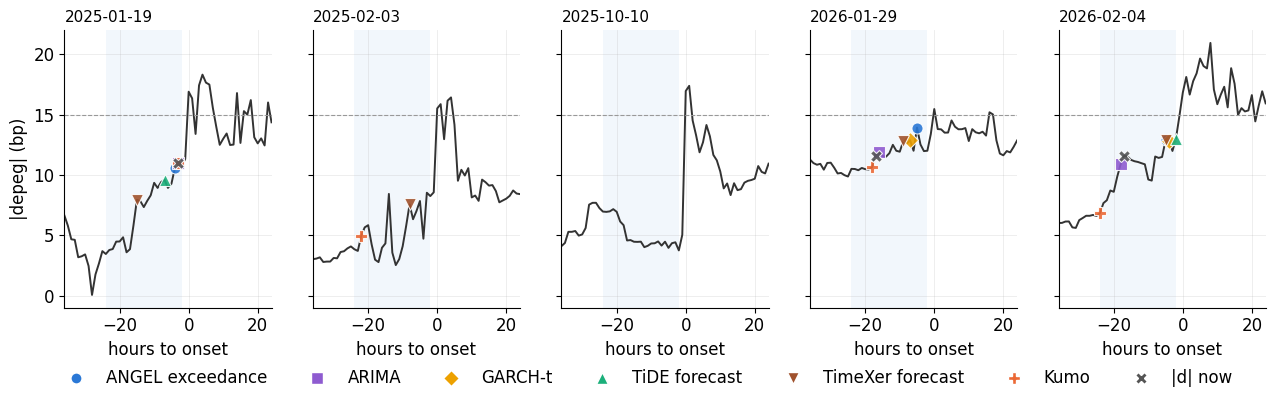

In [17]:
paths = pd.read_csv(DATA / "holdout_event_paths.csv"); al = pd.read_csv(DATA / "holdout_event_alerts.csv")
SHOW = ["ANGEL exceedance", "ARIMA", "GARCH-t", "TiDE forecast", "TimeXer forecast", "Kumo", "|d| now"]
MARK = dict(zip(SHOW, "osD^vPX"))
ev = list(dict.fromkeys(paths.event_time))
fig, axes = plt.subplots(1, len(ev), figsize=(3.1 * len(ev), 3.6), sharey=True)
for ax, e in zip(axes, ev):
    p = paths[paths.event_time.eq(e)]
    ax.plot(p.hours, p.depeg_bps.abs(), color="#333333", lw=1.4)
    ax.axhline(15, color="#999999", lw=0.8, ls="--"); ax.axvspan(-24, -2, color="#2a78d6", alpha=0.06, lw=0)
    a = al[al.event_time.eq(e) & al.detected.eq(1)]
    for m in SHOW:
        row = a[a.model.eq(m)]
        if len(row):
            ax.plot(-row.lead_hours, row.d_at_alert, marker=MARK[m], ls="none", ms=8, color=STYLE[m]["color"],
                    mec="white", mew=0.8, alpha=0.9)
    ax.set_title(pd.Timestamp(e).strftime("%Y-%m-%d"), fontsize=11, loc="left"); ax.set_xlim(-36, 24)
    ax.set_xlabel("hours to onset")
axes[0].set_ylabel("|depeg| (bp)")
h = [Line2D([], [], marker=MARK[m], ls="none", ms=8, color=STYLE[m]["color"], mec="white") for m in SHOW]
fig.legend(h, SHOW, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=len(SHOW))
save(fig, "B1_holdout_alert_timing")

## Take-aways

* **Probabilities.** Raw classifier probabilities are badly calibrated (Brier skill -0.2 to -2.8 in CV: class-weighted
  training), ARIMA's catastrophically so (-11); the forecasters' raw exceedance probabilities sit near or above
  climatology, and ANGEL's has the best raw skill on the holdout (+0.12). After recalibration every score is within
  +-0.08 of climatology in CV: hourly onset probabilities are hard; the value comes from *when* the rare alerts fire.
* **Main policy (calibrated P >= 0.1).** CV: ANGEL exceedance has the highest value (0.46), ahead of ARIMA (0.36),
  |d| (0.33) and GARCH-t (0.28); every direct classifier is <= 0.18 and the ANGEL network trained as a classifier is
  below zero. Holdout: the 2024 calibration map over-states probabilities after a 5x drop in the onset rate, and
  ANGEL falls to 0.13 (Kumo 0.27, TiDE 0.20); on its **raw** probability, which conditions on the current state and
  needs no map, ANGEL reaches 0.36, the best of all scores.
* **Threshold-free summary: decision curves.** Each model acts on the probability it could deploy before the test
  data (forecasters raw, classifiers Platt-calibrated); nothing else is tuned. Weighted by the LP cost-loss prior
  (section 5a): ANGEL 0.43 in CV and 0.42 on the holdout (seeds 0.39-0.44), first in both; GARCH-t 0.33 -> 0.11, TiDE
  0.20 -> 0.14; the Platt-calibrated classifiers are slightly positive in CV (0.04-0.10) and negative on the holdout
  (Kumo -0.16, random forest -0.17, CatBoost -0.03); TimeXer is negative in both; ARIMA's probability never falls
  below 0.5, so the rule is one continuous alert worth 0. The GPD-tail prior gives the same ranking (ANGEL 0.44 / 0.45).
  Platt scaling fitted on 2024 hurts every forecaster on the holdout (ANGEL 0.42 -> -0.22) after the drop in the
  onset rate; cutoffs tuned on validation do not carry over either (ARIMA leads CV at 0.21, worth 0 on the holdout).
* **Cost-loss prior.** From the LP backtest: a typical 15 bp event is not worth exiting for (fee surge > losses
  avoided); the expected loss is carried by the tail (USDC 2023-03, FTX), which puts users at r ~ 0.02-0.07. The
  ranking holds under every prior, but its level depends on how much weight the tail gets. Hand's neutral Beta(2, 2)
  makes every score negative: the rule does not pay for users with r >~ 0.2.
* **Lead time.** With a fixed cost per alert, value vanishes once an alert costs more than ~1-2 bp of a ~11 bp
  avoidable move; at low costs ANGEL and ARIMA lead in CV, and with 5 holdout events the lead-aware ranking is not
  conclusive. The simple cost-loss model ignores both lead time and the time spent hedged.